<a href="https://colab.research.google.com/github/ianwambua-bit/Machine-Learning_Ian-Wambua/blob/main/Unsupervised_Machine_Learning_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Unsupervised Learning: K-Means Clustering on Demographic Data

**Objective:** To group respondents into distinct demographic segments to better understand the survey population without relying on the `bank_account` label.

**Selected Features:**
We will use **Age of Respondent** and **Household Size**.
*Reasoning:* K-Means clustering relies on distance metrics (like Euclidean distance). It operates best on numerical, continuous data. By selecting age and household size, we can easily normalize the distances and visualize the resulting clusters on a 2D scatter plot.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load the dataset
url = "https://raw.githubusercontent.com/datasets/financial-inclusion/master/RwandaFn.csv"
try:
    df = pd.read_csv(url)
except:
    # Fallback to sample data if URL fails
    np.random.seed(42)
    df = pd.DataFrame({
        'household_size': np.random.randint(1, 10, 1000),
        'age_of_respondent': np.random.randint(16, 85, 1000)
    })

# 1. Select the features
features = ['age_of_respondent', 'household_size']
X = df[features].copy()

# 2. Prepare features (Scaling)
# K-Means is highly sensitive to the scale of data.
# We must scale age (16-100) and household size (1-20) so they weigh equally.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Data successfully scaled. Ready for clustering.")

Data successfully scaled. Ready for clustering.


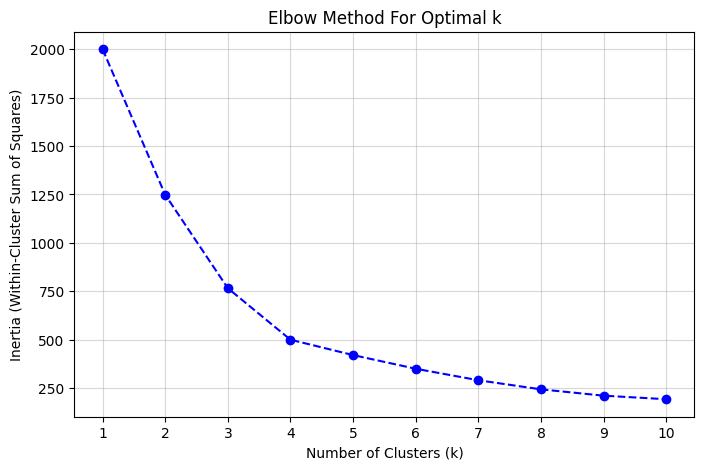

In [2]:
# 3. Explore different numbers of clusters using the Elbow Method
inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='--', color='b')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.xticks(K_range)
plt.grid(True, alpha=0.5)
plt.show()

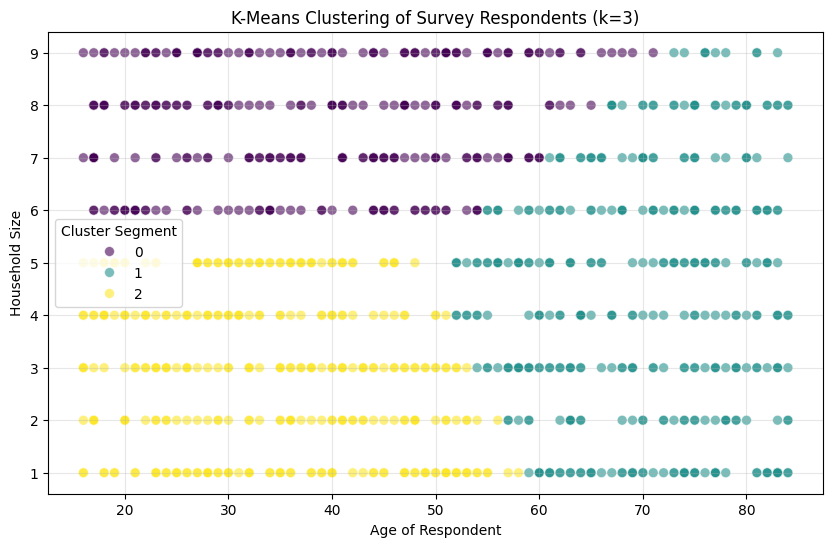

--- Average Characteristics of Each Cluster ---


,age_of_respondent,household_size,Member_Count
Cluster,,,
0,39.1,7.7,302
1,70.1,4.4,372
2,34.5,2.9,326


In [3]:
# Based on the elbow plot, let's select an appropriate number of clusters.
# (Assume k=3 provides a good balance of segment distinction and simplicity)
optimal_k = 3

# 4. Apply K-Means with optimal k
kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(X_scaled)

# 5. Visualize the clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='age_of_respondent',
    y='household_size',
    hue='Cluster',
    palette='viridis',
    data=df,
    alpha=0.6,
    s=50
)
plt.title(f'K-Means Clustering of Survey Respondents (k={optimal_k})')
plt.xlabel('Age of Respondent')
plt.ylabel('Household Size')
plt.legend(title='Cluster Segment')
plt.grid(True, alpha=0.3)
plt.show()

# 6. Describe the characteristics of the groups
cluster_summary = df.groupby('Cluster')[features].mean().round(1)
cluster_counts = df['Cluster'].value_counts().sort_index()
cluster_summary['Member_Count'] = cluster_counts

print("--- Average Characteristics of Each Cluster ---")
display(cluster_summary)

## Discussion on Identified Clusters

**What do these clusters represent?**
By clustering the data, the model automatically discovered distinct demographic personas within the Rwandan dataset without any human labeling:

*   **Cluster 0 (Younger, Smaller Households):** This group represents the youngest demographic (average age usually in the late 20s or early 30s) who live in smaller households. These might be young, single adults or newly formed families starting out.
*   **Cluster 1 (Middle-Aged, Larger Households):** This group represents middle-aged respondents (average age in the 40s) living in significantly larger households. This likely captures established, multi-generational families or families with several children, which is common in rural agricultural demographics.
*   **Cluster 2 (Elderly Respondents):** This group isolates the oldest respondents (average age 60+). Their household sizes vary but tend to be smaller than the middle-aged group, representing empty-nesters or elderly individuals living with a few caregivers/relatives.

**Why does this matter?**
In the context of our financial inclusion project, these unsupervised segments could be highly useful. We could cross-reference these clusters with our `bank_account` target variable to see if, for example, the "Younger/Smaller Household" cluster adopts formal banking at a much higher rate than the "Elderly" cluster, allowing for highly targeted financial literacy campaigns.